# Plot a Mork-2 training run

Reads `runs/<run>/metrics.csv` from `mork-train`. The most recently updated run is selected unless `RUN_NAME` is set.

In [36]:
import json
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

RUNS_DIR = Path("../runs")
RUN_NAME = None  # e.g. "20261018_120000" or "cool_18k"

# Most recently written run last; names like cool_18k don't sort by time.
runs = sorted(
    (p for p in RUNS_DIR.glob("*") if p.is_dir() and (p / "metrics.csv").exists()),
    key=lambda p: (p / "metrics.csv").stat().st_mtime,
)
print("available runs:", [r.name for r in runs] or "(none)")

if RUN_NAME is not None:
    RUN = RUNS_DIR / RUN_NAME
    assert (RUN / "metrics.csv").exists(), f"no metrics.csv in {RUN}"
elif runs:
    RUN = runs[-1]
else:
    RUN = None

train = val = None
if RUN is None:
    print(f"no runs yet under {RUNS_DIR.resolve()} — start one with mork-train")
else:
    print(f"plotting {RUN.name}")
    cfg_path = RUN / "config.json"
    if cfg_path.exists():
        cfg = json.loads(cfg_path.read_text())
        model = cfg.get("model", {})
        train_cfg = cfg.get("train", {})
        print(
            "config:",
            f"L{model.get('n_layer')} D{model.get('n_embd')} V{model.get('vocab_size')}",
            f"seq {train_cfg.get('seq_len')}",
            f"batch {train_cfg.get('batch_size')}",
            f"tokens/step {train_cfg.get('total_batch_size')}",
            f"max_lr {train_cfg.get('max_lr')}",
            f"max_steps {train_cfg.get('max_steps')}",
        )
    df = pd.read_csv(RUN / "metrics.csv")
    train = df.loc[df["split"] == "train"].copy()
    val = df.loc[df["split"] == "val"].copy()

available runs: ['cool_18k', '20261017_190144', 'cool_30k', '20261021_175650']
plotting 20261021_175650
config: L12 D768 V16384 seq 512 batch 4 tokens/step 32768 max_lr 0.0001 max_steps 2186


## Loss and learning rate

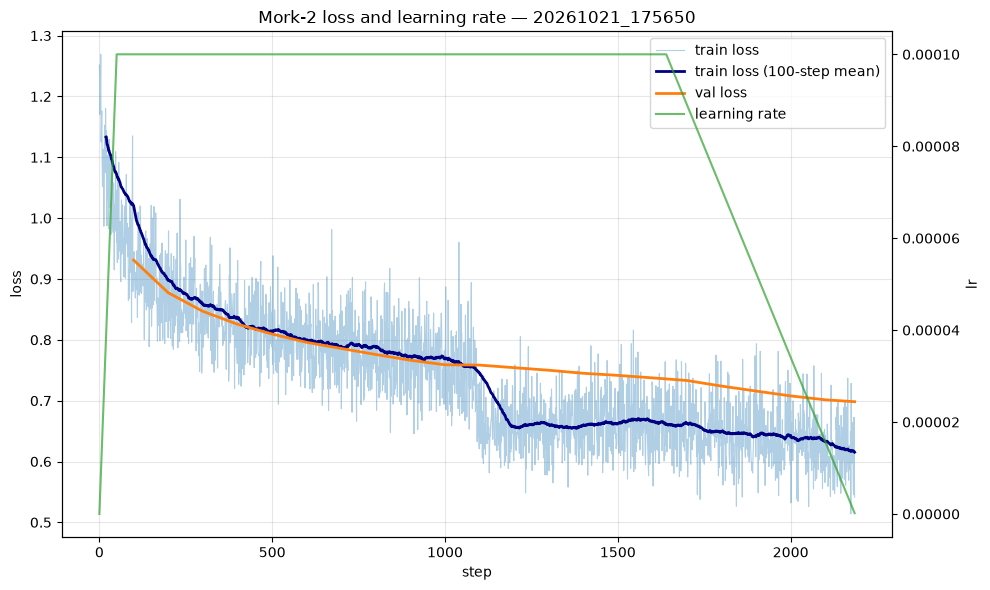

      step      loss            lr  grad_norm  tokens_per_sec     dt_ms
2202  2181  0.556228  9.157509e-07   0.504205        17082.55   1918.21
2203  2182  0.545347  7.326007e-07   0.522571        17142.65   1911.49
2204  2183  0.672725  5.494505e-07   0.587535        17097.90   1916.49
2205  2184  0.578664  3.663004e-07   0.542686        17194.36   1905.74
2206  2185  0.541369  1.831502e-07   0.511432          726.06  45131.37
      step      loss
1817  1799  0.724058
1918  1899  0.715876
2019  1999  0.707889
2120  2099  0.701487
2207  2185  0.698323


In [37]:
SMOOTH_STEPS = 100  # window for the averaged train-loss line

if train is None:
    print("nothing to plot yet")
else:
    fig, ax_loss = plt.subplots(figsize=(10, 6))
    ax_loss.plot(
        train["step"], train["loss"], label="train loss", linewidth=0.8, alpha=0.35, color="tab:blue"
    )
    smooth = train["loss"].rolling(SMOOTH_STEPS, min_periods=max(1, SMOOTH_STEPS // 5)).mean()
    ax_loss.plot(
        train["step"], smooth, label=f"train loss ({SMOOTH_STEPS}-step mean)", linewidth=2, color="navy"
    )
    if not val.empty:
        ax_loss.plot(val["step"], val["loss"], label="val loss", linewidth=2, color="tab:orange")
    ax_loss.set_ylabel("loss")
    ax_loss.set_xlabel("step")
    ax_loss.set_title(f"Mork-2 loss and learning rate — {RUN.name}")
    ax_loss.grid(True, alpha=0.3)

    ax_lr = ax_loss.twinx()
    ax_lr.plot(
        train["step"],
        train["lr"],
        label="learning rate",
        color="tab:green",
        linewidth=1.5,
        alpha=0.7,
    )
    ax_lr.set_ylabel("lr")

    lines, labels = ax_loss.get_legend_handles_labels()
    lines2, labels2 = ax_lr.get_legend_handles_labels()
    ax_loss.legend(lines + lines2, labels + labels2, loc="upper right")
    plt.tight_layout()
    plt.show()

    cols = [c for c in ("step", "loss", "lr", "grad_norm", "tokens_per_sec", "dt_ms") if c in train.columns]
    print(train[cols].tail())
    if not val.empty:
        print(val[["step", "loss"]].tail())

## Throughput

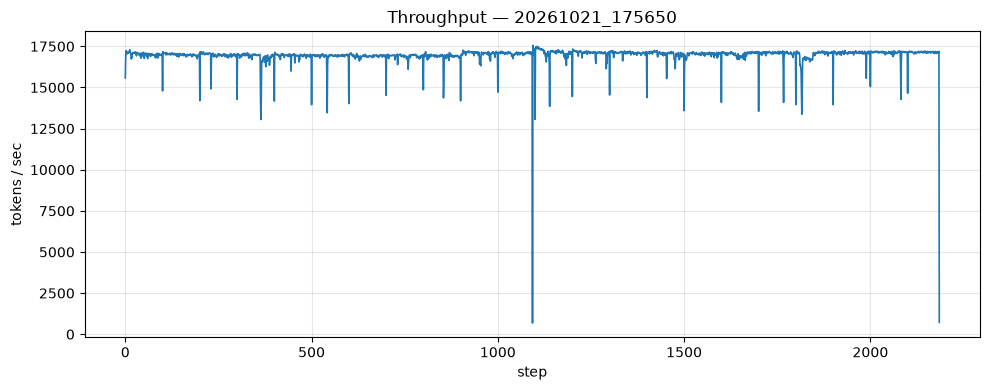

median tokens/sec: 17,040


In [38]:
if train is None:
    print("nothing to plot yet")
elif "tokens_per_sec" not in train.columns:
    print("no throughput column yet")
else:
    speed = train.dropna(subset=["tokens_per_sec"])
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(speed["step"], speed["tokens_per_sec"], linewidth=1.2)
    ax.set(xlabel="step", ylabel="tokens / sec", title=f"Throughput — {RUN.name}")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    print(f"median tokens/sec: {speed['tokens_per_sec'].median():,.0f}")

## Validation improvement

Skips the first few evals, then plots how much validation loss fell since the previous eval.

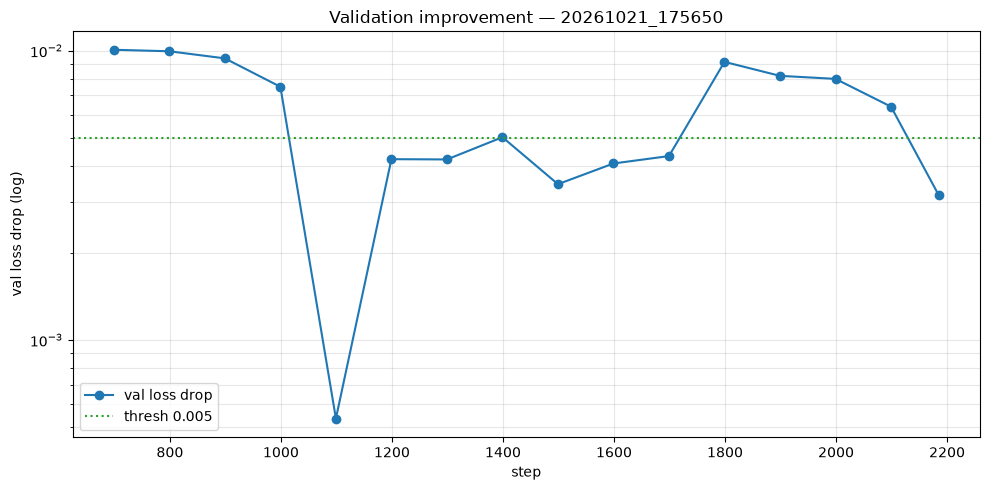

 step     loss  improve
 1299 0.750070 0.004206
 1399 0.745050 0.005020
 1499 0.741595 0.003455
 1599 0.737522 0.004073
 1699 0.733201 0.004321
 1799 0.724058 0.009143
 1899 0.715876 0.008182
 1999 0.707889 0.007987
 2099 0.701487 0.006402
 2185 0.698323 0.003164


In [39]:
SKIP_FIRST = 5
THRESH = 0.005

if val is None or val.empty:
    print("no validation points yet")
else:
    v = val.sort_values("step").assign(improve=lambda d: -d["loss"].diff())
    v = v.dropna(subset=["improve"]).iloc[SKIP_FIRST:]
    falling = v.loc[v["improve"] > 0]

    fig, ax = plt.subplots(figsize=(10, 5))
    if not falling.empty:
        ax.semilogy(falling["step"], falling["improve"], marker="o", label="val loss drop")
    ax.axhline(THRESH, color="tab:green", ls=":", label=f"thresh {THRESH}")
    ax.set(
        xlabel="step",
        ylabel="val loss drop (log)",
        title=f"Validation improvement — {RUN.name}",
    )
    ax.legend()
    ax.grid(True, which="both", alpha=0.3)
    plt.tight_layout()
    plt.show()

    if falling.empty:
        print("no positive validation drops in this window")
    else:
        print(falling[["step", "loss", "improve"]].tail(10).to_string(index=False))

## Milestone evals

Reads every `runs/*/loss_eval.csv` and `code_eval.csv`. Hot trunk snapshots are lines; cooled branches (`cool_*`) are markers so the cooldown lift is visible.

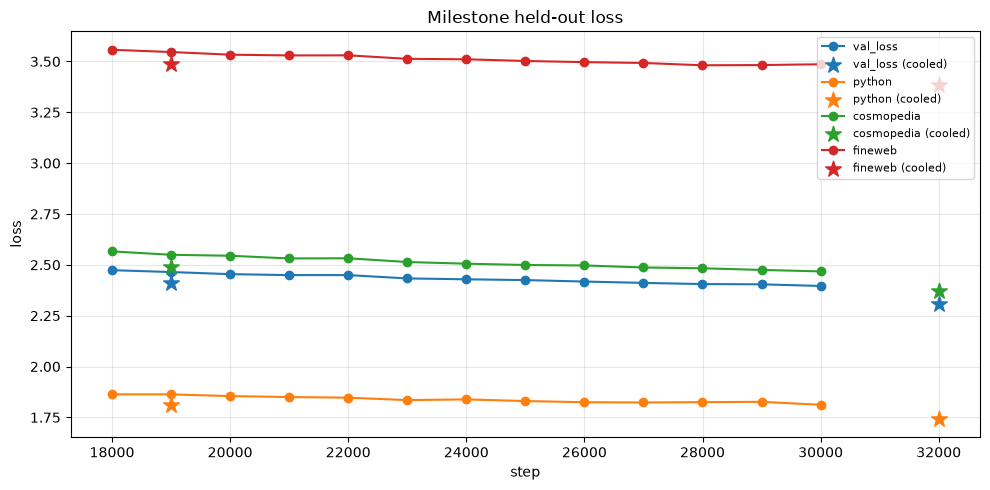

            run  step  val_loss   python  cosmopedia  fineweb
20261017_190144 17999  2.473696 1.863225    2.566173 3.557382
       cool_18k 18999  2.408316 1.811767    2.489322 3.488261
20261017_190144 18999  2.464584 1.863083    2.549377 3.546323
20261017_190144 19999  2.454167 1.854687    2.544696 3.533210
20261017_190144 20999  2.449542 1.849972    2.531493 3.529584
20261017_190144 21999  2.449506 1.846863    2.532198 3.530070
20261017_190144 22999  2.433187 1.834866    2.513822 3.512853
20261017_190144 23999  2.428870 1.838389    2.505599 3.510614
20261017_190144 24999  2.425006 1.830264    2.499187 3.502271
20261017_190144 25999  2.417797 1.824544    2.496925 3.496622
20261017_190144 26999  2.411139 1.823231    2.486942 3.492452
20261017_190144 27999  2.405485 1.824808    2.483111 3.481149
20261017_190144 28999  2.404188 1.826501    2.475001 3.482228
20261017_190144 29999  2.396116 1.811873    2.467696 3.486112
       cool_30k 31999  2.309357 1.744422    2.370129 3.384927


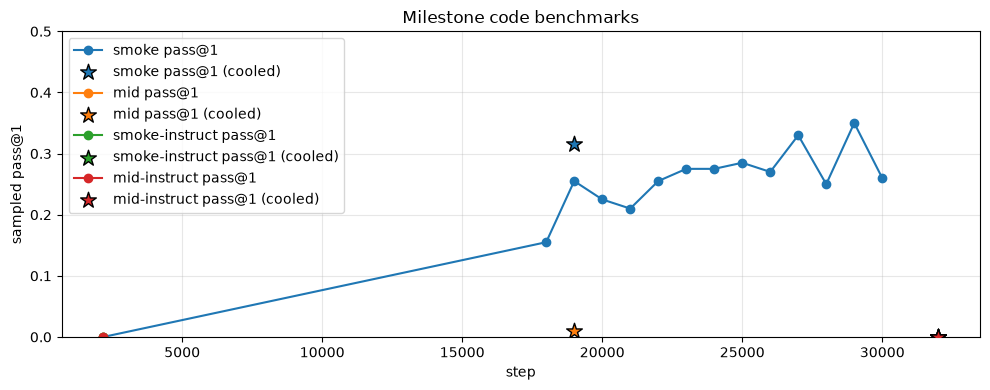

            run  step          tasks  greedy_pass  sample_pass_at_1  tasks_solved
20261021_175650  2185            mid           62             0.000             0
       cool_18k 18999            mid            3             0.010             8
       cool_30k 31999            mid            5             0.000             0
20261021_175650  2185   mid-instruct           58             0.000             0
       cool_30k 31999   mid-instruct            1             0.000             0
20261021_175650  2185          smoke           18             0.000             0
       cool_18k 17999          smoke            6             0.155            14
       cool_18k 18999          smoke           10             0.315            15
20261017_190144 18999          smoke            8             0.255            15
20261017_190144 19999          smoke            6             0.225            16
20261017_190144 20999          smoke            9             0.210            12
20261017_190144 

In [40]:
LOSS_COLS = ["val_loss", "python", "cosmopedia", "fineweb"]
SMOKE_COL = "sample_pass_at_1"
CODE_SETS = ["smoke", "mid", "smoke-instruct", "mid-instruct"]


def _load_eval_csvs(name: str) -> pd.DataFrame:
    frames = []
    for path in sorted(RUNS_DIR.glob(f"*/{name}")):
        df = pd.read_csv(path)
        if df.empty:
            continue
        df["run"] = path.parent.name
        frames.append(df)
    if not frames:
        return pd.DataFrame()
    out = pd.concat(frames, ignore_index=True)
    out["checkpoint"] = out["checkpoint"].map(lambda p: str(Path(p).expanduser().resolve()))
    # Cool branches live under checkpoints/cool_*/; don't trust the CSV's run folder
    # (an --out path can put a hot snapshot into a cool_* CSV).
    out["cooled"] = out["checkpoint"].map(
        lambda p: any(part.startswith("cool") for part in Path(p).parts)
    )
    # Keep the newest row for each checkpoint (+ task label for code).
    keys = ["checkpoint"] + (["tasks"] if "tasks" in out.columns else [])
    return out.sort_values("time").drop_duplicates(keys, keep="last")


loss_eval = _load_eval_csvs("loss_eval.csv")
code_eval = _load_eval_csvs("code_eval.csv")
if not code_eval.empty:
    code_eval = code_eval.loc[code_eval["tasks"].astype(str).isin(CODE_SETS)].copy()

if loss_eval.empty and code_eval.empty:
    print("no milestone CSVs yet — run mork-eval --tasks loss smoke")
else:
    if not loss_eval.empty:
        fig, ax = plt.subplots(figsize=(10, 5))
        for col in LOSS_COLS:
            if col not in loss_eval.columns:
                continue
            hot = loss_eval.loc[~loss_eval["cooled"]].sort_values("step")
            cool = loss_eval.loc[loss_eval["cooled"]].sort_values("step")
            if not hot.empty:
                ax.plot(hot["step"], hot[col], marker="o", linewidth=1.5, label=col)
            if not cool.empty:
                ax.scatter(
                    cool["step"],
                    cool[col],
                    marker="*",
                    s=140,
                    zorder=5,
                    label=f"{col} (cooled)",
                )
        ax.set(
            xlabel="step",
            ylabel="loss",
            title="Milestone held-out loss",
        )
        ax.grid(True, alpha=0.3)
        ax.legend(loc="best", fontsize=8)
        plt.tight_layout()
        plt.show()
        print(loss_eval[["run", "step", *LOSS_COLS]].sort_values("step").to_string(index=False))

    if not code_eval.empty:
        fig, ax = plt.subplots(figsize=(10, 4))
        for i, task_set in enumerate(CODE_SETS):
            rows = code_eval.loc[code_eval["tasks"] == task_set]
            hot = rows.loc[~rows["cooled"]].sort_values("step")
            cool = rows.loc[rows["cooled"]].sort_values("step")
            color = f"C{i}"
            if not hot.empty:
                ax.plot(
                    hot["step"],
                    hot[SMOKE_COL],
                    marker="o",
                    linewidth=1.5,
                    color=color,
                    label=f"{task_set} pass@1",
                )
            if not cool.empty:
                ax.scatter(
                    cool["step"],
                    cool[SMOKE_COL],
                    marker="*",
                    s=140,
                    color=color,
                    edgecolor="black",
                    zorder=5,
                    label=f"{task_set} pass@1 (cooled)",
                )
        ax.set(
            xlabel="step",
            ylabel="sampled pass@1",
            title="Milestone code benchmarks",
            ylim=(0, max(0.5, float(code_eval[SMOKE_COL].max()) + 0.05)),
        )
        ax.grid(True, alpha=0.3)
        ax.legend(loc="best")
        plt.tight_layout()
        plt.show()
        cols = [c for c in ("run", "step", "tasks", "greedy_pass", SMOKE_COL, "tasks_solved") if c in code_eval.columns]
        print(code_eval[cols].sort_values(["tasks", "step"]).to_string(index=False))